In [7]:
import sys
from pathlib import Path
import pickle
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import glob
import os

ROOT_DIR = Path.cwd().parent
sys.path.append(str(ROOT_DIR))
CALIBRATION_DIR = ROOT_DIR / "data/calibration_results"

import open3d as o3d

from src.reconstruction import (
    get_pair_index,
    build_local_point_cloud,
    create_charuco_detector,
    estimate_global_pose,
)

from src.utils.plotting import (
    show_disparity,
    show_geometries,
    save_open3d_screenshot,
)

# 1. Stereo Matching

Disparidades guardadas en ../data/processed/palacio/disparity/ (72 pares)


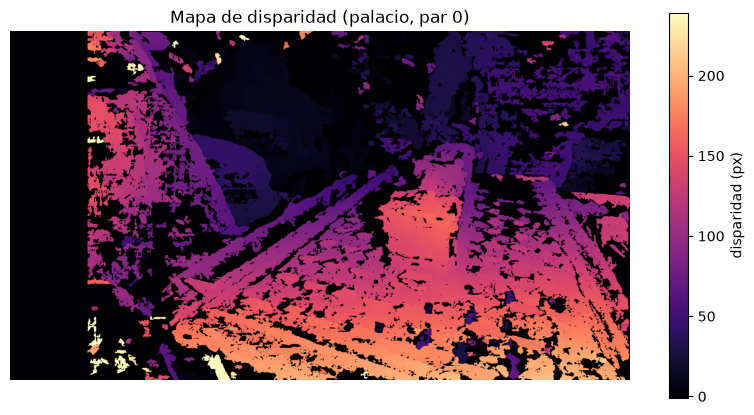

In [8]:
# --- 1. Stereo Matching: rectificar cada par y calcular su disparidad ---
dataset_name = "palacio"                       # dataset de reconstrucción a procesar
dataset_dir = f"../data/raw/{dataset_name}/"
disparity_output_dir = f"../data/processed/{dataset_name}/disparity/"
os.makedirs(disparity_output_dir, exist_ok=True)

# Mapas de rectificación precalculados
with (CALIBRATION_DIR / "stereo_maps.pkl").open("rb") as f:
    maps = pickle.load(f)
left_rectification_map_x = np.array(maps['left_map_x'])
left_rectification_map_y = np.array(maps['left_map_y'])
right_rectification_map_x = np.array(maps['right_map_x'])
right_rectification_map_y = np.array(maps['right_map_y'])

# Parámetros de StereoSGBM (num_disparities debe ser múltiplo de 16)
block_size = 11
min_disparity, num_disparities = 0, 240
stereo = cv.StereoSGBM_create(
    minDisparity=min_disparity,
    numDisparities=num_disparities,
    blockSize=block_size,
    P1=8 * 1 * block_size**2,
    P2=32 * 1 * block_size**2,
    disp12MaxDiff=1,
    uniquenessRatio=5,
    speckleWindowSize=200,
    speckleRange=2,
    preFilterCap=0,
    mode=cv.STEREO_SGBM_MODE_SGBM,
)

images_left = sorted(
    glob.glob(os.path.join(dataset_dir, 'left_*.jpg')), key=get_pair_index
)
images_right = sorted(
    glob.glob(os.path.join(dataset_dir, 'right_*.jpg')), key=get_pair_index
)

for img_left_path, img_right_path in zip(images_left, images_right):
    left_image_gray = cv.imread(img_left_path, cv.IMREAD_GRAYSCALE)
    right_image_gray = cv.imread(img_right_path, cv.IMREAD_GRAYSCALE)
    if left_image_gray is None or right_image_gray is None:
        continue

    rectified_left_gray = cv.remap(
        left_image_gray,
        left_rectification_map_x,
        left_rectification_map_y,
        cv.INTER_LINEAR,
    )
    rectified_right_gray = cv.remap(
        right_image_gray,
        right_rectification_map_x,
        right_rectification_map_y,
        cv.INTER_LINEAR,
    )

    # SGBM devuelve la disparidad en enteros escalados x16 -> pasar a float real
    disparity = (
        stereo.compute(rectified_left_gray, rectified_right_gray).astype(np.float32)
        / 16.0
    )

    disparity_filename_stem = (
        os.path.basename(img_left_path)
        .replace('left', 'disp')
        .replace('.jpg', '')
    )
    # Disparidad REAL (float): es la que usa la nube local. NO usar el PNG para 3D.
    np.save(
        os.path.join(disparity_output_dir, disparity_filename_stem + '.npy'),
        disparity,
    )
    # PNG normalizado solo para visualización / informe
    disparity_preview = cv.normalize(
        disparity, None, 0, 255, cv.NORM_MINMAX, cv.CV_8U
    )
    cv.imwrite(
        os.path.join(disparity_output_dir, disparity_filename_stem + '.png'),
        disparity_preview,
    )

print(f"Disparidades guardadas en {disparity_output_dir} ({len(images_left)} pares)")

# Visualización de un mapa de disparidad representativo
disparity_example = np.load(os.path.join(disparity_output_dir, 'disp_0.npy'))
show_disparity(
    disparity_example,
    title=f'Mapa de disparidad ({dataset_name}, par 0)',
    save_path=f'../report/report_images/disparidad_{dataset_name}.png',
)
plt.show()

# 2. Computar Nube local

In [9]:
# --- 2. Nube local: ejemplo de nube de puntos de un par ---
# La función construir_nube_local vive en src/reconstruction.py
Q = np.array(maps['Q'])              # matriz de reproyección (de la rectificación)
Z_MIN, Z_MAX = 100.0, 2000.0         # rango de profundidad válido en mm

disparity_0 = np.load(f"../data/processed/{dataset_name}/disparity/disp_0.npy")
point_cloud_0 = build_local_point_cloud(
    f"../data/raw/{dataset_name}/left_0.jpg",
    disparity_0,
    Q,
    left_rectification_map_x,
    left_rectification_map_y,
    min_disparity=min_disparity,
    z_min=Z_MIN,
    z_max=Z_MAX,
)
print(f"Nube local del par 0: {len(point_cloud_0.points):,} puntos")
show_geometries([point_cloud_0], title=f"Nube local - par 0 ({dataset_name})")

Nube local del par 0: 956,210 puntos


# 3. Pose global

In [10]:
# --- 3. Pose global: tablero ChArUco y pose de la cámara ---
# Las funciones crear_detector_charuco y estimar_pose_global están en src/reconstruction.py.
# La pose se estima sobre la imagen RECTIFICADA, con la intrínseca rectificada P1.
P1 = np.array(maps['P1'])
rectified_intrinsic = P1[:3, :3]
charuco_board, charuco_detector = create_charuco_detector()

# Prueba sobre el primer par del dataset
_left_image_gray = cv.imread(
    f'../data/raw/{dataset_name}/left_0.jpg', cv.IMREAD_GRAYSCALE
)
_rectified_left_gray = cv.remap(
    _left_image_gray,
    left_rectification_map_x,
    left_rectification_map_y,
    cv.INTER_LINEAR,
)
camera_to_world_transform_0 = estimate_global_pose(
    _rectified_left_gray, charuco_detector, charuco_board, rectified_intrinsic
)
if camera_to_world_transform_0 is None:
    print('No se detectó el tablero en el par 0.')
else:
    print('Pose del par 0 (cámara rectificada -> mundo):')
    print(np.round(camera_to_world_transform_0, 2))
    print(f'Posición de la cámara en el mundo: {np.round(camera_to_world_transform_0[:3, 3], 1)} mm')

Pose del par 0 (cámara rectificada -> mundo):
[[ 9.6000e-01  1.4000e-01 -2.4000e-01  2.4522e+02]
 [-2.8000e-01  3.9000e-01 -8.8000e-01  6.8352e+02]
 [-3.0000e-02  9.1000e-01  4.1000e-01 -2.1139e+02]
 [ 0.0000e+00  0.0000e+00  0.0000e+00  1.0000e+00]]
Posición de la cámara en el mundo: [ 245.2  683.5 -211.4] mm


# 4. Transformación

In [11]:
# --- 4. Transformación: llevar cada nube local al marco de mundo y fusionarlas ---
disparity_dir = f"../data/processed/{dataset_name}/disparity/"
dataset_output_dir  = f"../data/processed/{dataset_name}/"
os.makedirs(dataset_output_dir, exist_ok=True)

images_left = sorted(
    glob.glob(os.path.join(f"../data/raw/{dataset_name}/", 'left_*.jpg')),
    key=get_pair_index,
)

global_point_cloud = o3d.geometry.PointCloud()
camera_frames = []                                   # poses de cámara para visualizar
merged_pair_count, discarded_pair_count = 0, 0

for left_path in images_left:
    disparity_filename_stem = (
        os.path.basename(left_path)
        .replace('left', 'disp')
        .replace('.jpg', '')
    )
    disparity_file_path = os.path.join(
        disparity_dir, disparity_filename_stem + '.npy'
    )
    if not os.path.exists(disparity_file_path):
        continue
    disparity = np.load(disparity_file_path)

    # Pose de esta cámara respecto del mundo (tablero ChArUco)
    left_image_gray = cv.imread(left_path, cv.IMREAD_GRAYSCALE)
    rectified_left_gray = cv.remap(
        left_image_gray,
        left_rectification_map_x,
        left_rectification_map_y,
        cv.INTER_LINEAR,
    )
    camera_to_world_transform = estimate_global_pose(
        rectified_left_gray, charuco_detector, charuco_board, rectified_intrinsic
    )
    if camera_to_world_transform is None:                       # sin tablero detectado -> se descarta el par
        discarded_pair_count += 1
        continue

    # Nube local y TRANSFORMACIÓN cámara -> mundo
    point_cloud_i = build_local_point_cloud(
        left_path,
        disparity,
        Q,
        left_rectification_map_x,
        left_rectification_map_y,
        min_disparity=min_disparity,
        z_min=Z_MIN,
        z_max=Z_MAX,
    )
    point_cloud_i.transform(camera_to_world_transform)
    global_point_cloud += point_cloud_i

    # Pose de la cámara (marco de ejes) para verificar la órbita de captura
    camera_frame = o3d.geometry.TriangleMesh.create_coordinate_frame(size=40)
    camera_frame.transform(camera_to_world_transform)
    camera_frames.append(camera_frame)
    merged_pair_count += 1

print(f"Pares fusionados: {merged_pair_count} | descartados sin tablero: {discarded_pair_count}")
print(f"Puntos en la nube global: {len(global_point_cloud.points):,}")

# Guardar la nube global fusionada (sin optimizar aún -> insumo del notebook 03)
global_point_cloud_path = os.path.join(
    dataset_output_dir, f"nube_global_{dataset_name}.ply"
)
o3d.io.write_point_cloud(global_point_cloud_path, global_point_cloud)
print("Nube global guardada en", global_point_cloud_path)

# Escena de verificación: nube + origen del mundo (tablero) + poses de cámara
world_origin = o3d.geometry.TriangleMesh.create_coordinate_frame(size=100)
scene_geometries = [global_point_cloud, world_origin, *camera_frames]

# Guardar la figura para el informe (render offscreen) y mostrar la escena
save_open3d_screenshot(
    scene_geometries, f'../report/report_images/poses_{dataset_name}.png'
)
print(f"Figura de poses guardada en report/report_images/poses_{dataset_name}.png")

show_geometries(scene_geometries, title=f"Nube global en el marco de mundo ({dataset_name})")

Pares fusionados: 69 | descartados sin tablero: 3
Puntos en la nube global: 72,303,352
Nube global guardada en ../data/processed/palacio/nube_global_palacio.ply
Figura de poses guardada en report/report_images/poses_palacio.png
